# An honest estimate: data splits, cross-validation and leakage

*Session 7, block 1 · Course material, CC BY 4.0. Sections marked "Adapted from" reuse third-party material under its licence (see [Further reading](#Further-reading)).*

After this block you can split labelled data into training, validation and test sets and say what each one is for, estimate a model's performance with k-fold, stratified, grouped and time-series cross-validation, put a bootstrap confidence interval around a test metric, and recognise and fix the two most common forms of data leakage with a scikit-learn `Pipeline` and the right splitter.

The running question: **how far off would a price model be for a host who lists a first flat in Berlin?** In Session 6 you split the data once and reported one test score. Here you learn why that number is not enough, and how to get one you can defend.

## Teaching map

The **core path** (45 minutes) is marked with a ✔. Sections labelled *(depth: self-study or if time allows)* go further and can be skipped in class; students work through them at home.

| # | Section | Core min | What it delivers |
|---|---|---|---|
| 0 | The case: a price for a first-time host | 2 ✔ | the Berlin price table, the target, the host groups |
| 1 | Training, validation and test data and their roles | 5 ✔ | three jobs, three sets; training error versus test error |
| 2 | Why a single split is unreliable | 4 ✔ | the score is a random variable; 20 splits, 20 numbers |
| 3 | k-fold and stratified cross-validation | 6 ✔ | `KFold`, `cross_val_score`, `cross_validate`, `StratifiedKFold` |
| 4 | Grouped and time-series splits | 7 ✔ | `GroupKFold` by host, `TimeSeriesSplit`, choosing a splitter |
| 5 | Bootstrap confidence interval of a metric | 6 ✔ | listing and host (cluster) bootstrap of the MAE in euros |
| 6 | Data leakage: preprocessing outside the cross-validation | 4 ✔ | why steps that learn must not see the validation rows |
| 7 | Data leakage: target leakage | 3 ✔ | the host's mean price: a feature that contains the answer |
| 8 | Preprocessing inside a Pipeline | 4 ✔ | the fix for leak 1; grouped folds as the fix for leak 2 |
| 9 | Worked example: the check on new hosts | 4 ✔ | which validation promise came true |
| | Check your understanding, exercises, debrief | 45 | |

```mermaid
flowchart LR
    A["All labelled data"] --> B["Development data"]
    A --> T["Test set<br/>(locked away)"]
    B --> CV["Cross-validation:<br/>train and validate k times,<br/>preprocessing inside a Pipeline"]
    CV --> C["Choose model and<br/>settings"]
    C --> F["Refit on all<br/>development data"]
    F --> E["Evaluate once<br/>on the test set"]
    T --> E
```

The code cells build on each other; run them in order. The first cell moves to the repository root, where the case-study paths start. The data are the Inside Airbnb listings for Berlin in `case-study/data/airbnb/` (create them with `uv run python case-study/prepare_airbnb.py`, see [case-study/README.md](../../../case-study/README.md)). Two small sections download the IBM Telco churn table from GitHub.

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

## 0 · The case: a price for a first-time host

A new host wants to know what to charge for a flat. A price model learned from the listings already on Airbnb could suggest a price. Before anyone relies on it, we must answer one question honestly: **how far off will the suggestion typically be, in euros, for a host the model has never seen?** Everything in this block serves that question.

The table is the short-stay table of Sessions 4–6: listings with a price and a minimum stay below 28 nights (longer minimum stays are medium-term rentals with another price basis), without the listings priced below €10 or above €1,000, which Session 4 treats as outliers. The target is the **log of the nightly price**: errors on the log scale are relative errors, and `np.exp` turns predictions back into euros.

Next we load the listings and build the feature table. `pd.get_dummies(df, columns=[...])` turns the room type and the district into 0/1 columns; `np.hypot` computes the straight-line distance to Alexanderplatz from the coordinates.

In [2]:
import numpy as np
import pandas as pd

lst = pd.read_parquet("case-study/data/airbnb/listings.parquet")
bnb = lst[(lst["minimum_nights"] < 28) & lst["price"].between(10, 1000)].reset_index(drop=True)
bnb["dist_km"] = np.hypot((bnb["latitude"] - 52.5219) * 111.2,   # km to Alexanderplatz
                          (bnb["longitude"] - 13.4132) * 68.0)
cols = ["accommodates", "bedrooms", "beds", "bathrooms", "dist_km", "room_type", "district",
        "number_of_reviews", "review_scores_rating", "availability_365"]
X = pd.get_dummies(bnb[cols], columns=["room_type", "district"], dtype=int)
y = np.log(bnb["price"])                  # target: log of the nightly price in EUR
price, hosts = bnb["price"], bnb["host_id"]
print(len(bnb), "listings,", hosts.nunique(), "hosts,", X.shape[1], "columns; median price EUR", price.median())

6675 listings, 3737 hosts, 24 columns; median price EUR 156.61


> **Note.** Inside Airbnb collects these data from public listing pages (CC BY 4.0; snapshot of 26 June 2026). The course copy has no host names. Use `host_id` only as a grouping key and report results in aggregate; never look up or name individual hosts.

The model is gradient boosting (`HistGradientBoostingRegressor`, explained in Session 10; here a black box that handles missing values on its own). We also write a small function that turns errors on the log scale back into a **mean absolute error (MAE) in euros**, the number a host understands, and wrap it with `make_scorer` so that the cross-validation tools of section 2 onwards can use it.

In [3]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import make_scorer


def mae_eur(y_log_true, y_log_pred):
    # Mean absolute error in euros, computed from log prices.
    return np.mean(np.abs(np.exp(y_log_true) - np.exp(y_log_pred)))


eur = make_scorer(mae_eur, greater_is_better=False)   # the same metric for cross-validation (section 2)
gbm = HistGradientBoostingRegressor(random_state=0)

## 1 · Training, validation and test data and their roles

**Concept.** Labelled data are used for three different jobs, and each job needs its own rows.

- The **training set** is used to *fit* the model: the algorithm sees these rows and their labels and chooses its parameters (for example the coefficients of a regression or the split points of a tree).
- The **validation set** is used to *make choices*: which model, which features, which settings. We compare candidates by their validation score.
- The **test set** is used *once, at the end*, to estimate how well the chosen model will perform on new data. It must not influence any choice.

An everyday analogy: a student practises with exercises (training), takes mock exams to decide how to revise (validation), and sits the real exam once (test). If the real exam questions leak into the mock exams, the mock score says nothing about the real one.

A worked example. A bank has 10,000 past loan applications with known outcomes. It keeps 2,000 aside as the test set. Of the remaining 8,000 it uses 6,000 to fit three candidate models and 2,000 to compare them. Model B wins on the validation rows. Only now does the bank score model B on the 2,000 test applications. That number is an honest estimate because no decision depended on the test rows. The validation score of model B is slightly optimistic: B was chosen *because* it did well on those rows.

**Why it matters.** Each time a score is used to make a decision, the rows behind it stop being "new data". If you choose a model by its test score, the test score is no longer an unbiased estimate; with enough candidates one of them will look good by chance. In this course the leaderboard of Sessions 13–16 plays the role of the test set: its labels are hidden, so nobody can tune on them.

### Training error versus test error

*Adapted from "Cross-validation framework" ([INRIA scikit-learn MOOC](https://inria.github.io/scikit-learn-mooc/) (INRIA, CC BY 4.0)).*

The first reason for keeping rows out is that a model's error on its own training data says almost nothing about new data. A fully grown decision tree is the extreme case: it keeps splitting until every training row sits in its own leaf, so it reproduces every training price exactly. The error measured on the training rows is called the **training error** (or empirical error); the error on rows not seen during training is the **test error** (or generalisation error). We want to minimise the second, but `fit` can only minimise the first.

**Predict before running:** what MAE will a fully grown tree have on the rows it was trained on?

Next we fit a `DecisionTreeRegressor` (no depth limit) on all listings and score it on the same rows, then repeat with a 75/25 `train_test_split`, which shuffles the rows and returns training and test parts of `X` and `y`.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

tree = DecisionTreeRegressor(random_state=0).fit(X.fillna(-1), y)    # a tree needs no missing values here
print(f"training error on all rows: MAE EUR {mae_eur(y, tree.predict(X.fillna(-1))):.1f}")

a_tr, a_te, b_tr, b_te = train_test_split(X.fillna(-1), y, random_state=0)
tree.fit(a_tr, b_tr)
print(f"training error: MAE EUR {mae_eur(b_tr, tree.predict(a_tr)):.1f}")
print(f"test error:     MAE EUR {mae_eur(b_te, tree.predict(a_te)):.1f}")

training error on all rows: MAE EUR 0.0
training error: MAE EUR 0.0
test error:     MAE EUR 67.7


The tree has memorised the training listings (an error of a few cents at most comes from listings with identical features but different prices), while on unseen listings it is off by 67.7 euros on average. A perfect score on training data almost always reveals a methodological problem, not a perfect model.

### A three-way split in Python

Next we make a 60/20/20 split with two calls of `train_test_split`: first 20 % of the rows become the test set, then 25 % of the remaining 80 % become the validation set. `random_state=0` makes the split reproducible.

In [5]:
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
X_tr, X_val, y_tr, y_val = train_test_split(X_dev, y_dev, test_size=0.25, random_state=0)
print(len(X_tr), "training,", len(X_val), "validation,", len(X_test), "test listings")

4005 training, 1335 validation, 1335 test listings


Now we use the validation set for a decision: does the model need all columns, or are size and location enough? `X_tr[use]` selects the listed columns.

In [6]:
few = ["accommodates", "bedrooms", "dist_km"]
for name, use in [("3 columns", few), ("all columns", list(X.columns))]:
    gbm.fit(X_tr[use], y_tr)
    print(f"{name:12s} validation MAE EUR {mae_eur(y_val, gbm.predict(X_val[use])):.1f}")

3 columns    validation MAE EUR 54.6


all columns  validation MAE EUR 47.9


All columns win on the validation set. Only now do we touch the test set: we refit the chosen model on training plus validation rows (more data, same decision) and score it **once**.

In [7]:
gbm.fit(X_dev, y_dev)                     # refit the chosen model on training + validation rows
print(f"test MAE EUR {mae_eur(y_test, gbm.predict(X_test)):.1f}")   # the one look at the test rows

test MAE EUR 47.3


**In practice.**
- The Netflix Prize (2006–2009) kept a "quiz" set for the public leaderboard and a separate hidden "test" set that decided the winner, so that teams could not win by tuning to the leaderboard.
- The TRIPOD reporting guideline for clinical prediction models (Collins et al., 2015) asks authors to state how data were split for development and validation, and treats a separate external test as stronger evidence than internal validation.
- Kaggle competitions rank by a private part of the test set at the end; rankings often move between the public and private leaderboards ("shake-up"), which shows how much teams had adapted to the public part.

> **Note.** Looking at the test score "just to see" and then changing the model turns the test set into a validation set. Decide on the model first, then look at the test score once and report it, even if it is disappointing.

> **Note.** Fix `random_state` in every split and every model that uses randomness. Then a colleague who runs your notebook gets the same numbers.

> 📖 **Read more:** [extras/01-model-validation.ipynb](extras/01-model-validation.ipynb) (Python Data Science Handbook, ch. 5.3): a 1-nearest-neighbour model that scores 100 % on its own training data, then holdout sets and two-fold cross-validation on the iris data.

## 2 · Why a single split is unreliable

**Concept.** A test score is computed on a finite, randomly chosen set of rows. Another random split puts other listings into the test set and gives another score. The score is therefore a **random variable**: it has a mean (the quantity we want, the expected error on new data) and a spread (noise caused by the particular split). The spread shrinks with the size of the test set. For accuracy the standard error is roughly √(p(1 − p)/n): with p = 0.8 and n = 1,761 test customers this is about one percentage point; with n = 200 it is almost three points.

**Why it matters.** Model comparisons, setting choices and project reports all rest on such estimates. If the score moves by two euros when only the seed changes, an "improvement" of one euro is not evidence. A single split also wastes data: the test rows never help to train, and the training rows never help to evaluate. We may have been lucky and put the easiest listings into the test set by chance.

**Predict before running:** the same model, 20 different random 75/25 splits. How far apart will the best and the worst MAE be?

Next we loop over 20 seeds. `random_state=seed` gives a different shuffle in each round.

In [8]:
scores = []
for seed in range(20):
    a_tr, a_te, b_tr, b_te = train_test_split(X, y, test_size=0.25, random_state=seed)
    scores.append(mae_eur(b_te, gbm.fit(a_tr, b_tr).predict(a_te)))
print("lowest, mean, highest MAE EUR:", np.round([min(scores), np.mean(scores), max(scores)], 1))
print("standard deviation EUR:", round(np.std(scores), 1))

lowest, mean, highest MAE EUR: [44.9 47.2 49.7]
standard deviation EUR: 1.1


Between 44.9 and 49.7 euros, only because a different set of listings landed in the test part. One number hides that spread.

**In practice.**
- Kaggle "shake-ups": in competitions with small test sets, teams that ranked high on the public leaderboard regularly drop many places on the private one, because the public part was too small to separate models.
- Recht et al. (2019) built new test sets for CIFAR-10 and ImageNet and found accuracy drops of 3–15 percentage points on the new samples; they attribute the drops mainly to small differences in how the new images were collected. A test score is tied to its particular test sample.

> **Note.** Never report a difference between two models that is smaller than the spread of the score across splits as an improvement. Report the spread (or an interval) with the score.

### Repeated random splits with `ShuffleSplit` *(depth: self-study or if time allows)*

*Adapted from "Cross-validation framework" ([INRIA scikit-learn MOOC](https://inria.github.io/scikit-learn-mooc/) (INRIA, CC BY 4.0)) and from ISLP Lab 5 ([ISLP labs](https://github.com/intro-stat-learning/ISLP_labs), BSD-2-Clause).*

The loop above is so common that scikit-learn has an object for it. A **splitter** (cross-validation iterator) only produces row indices; `cross_validate` takes a model, the data and a splitter, fits a fresh copy of the model on each training part and scores it on the matching test part. **Shuffle-split** repeats the procedure *n* times: shuffle a copy of the data, split it into a training and a test part, fit, score. The cost grows with `n_splits`, and all *n* fitted models are thrown away: we only keep their scores.

![Shuffle-split cross-validation with five splits: in each row the training samples and the test samples are drawn at random from the shuffled data.](../figures/shufflesplit_diagram.png)

*Figure: INRIA scikit-learn MOOC, CC BY 4.0.*

A detail of the API: the `scoring` argument always expects a **score**, where higher is better. Error metrics are therefore passed with a `neg_` prefix (`"neg_mean_absolute_error"`), or, as with our `eur` scorer from section 0, built with `make_scorer(..., greater_is_better=False)`, which also returns the negative error. We flip the sign back afterwards.

Next we run 40 shuffle-splits with 30 % test rows and collect the results in a DataFrame. `cross_validate` returns a dictionary with `fit_time`, `score_time` and `test_score` arrays, one entry per split.

In [9]:
from sklearn.model_selection import ShuffleSplit, cross_validate

cv_results = pd.DataFrame(cross_validate(gbm, X, y, scoring=eur,
                                         cv=ShuffleSplit(n_splits=40, test_size=0.3, random_state=0)))
cv_results["test_error"] = -cv_results["test_score"]
cv_results.head()

,fit_time,score_time,test_score,test_error
0,0.422595,0.010274,-47.676889,47.676889
1,0.476621,0.007507,-47.595850,47.595850
2,0.220316,0.005550,-47.095768,47.095768
3,0.196124,0.005377,-47.935984,47.935984
4,0.171324,0.006013,-47.793618,47.793618


With 40 errors we can draw their distribution and compare its width with the natural spread of the target. `Series.plot.hist` draws a histogram with pandas.

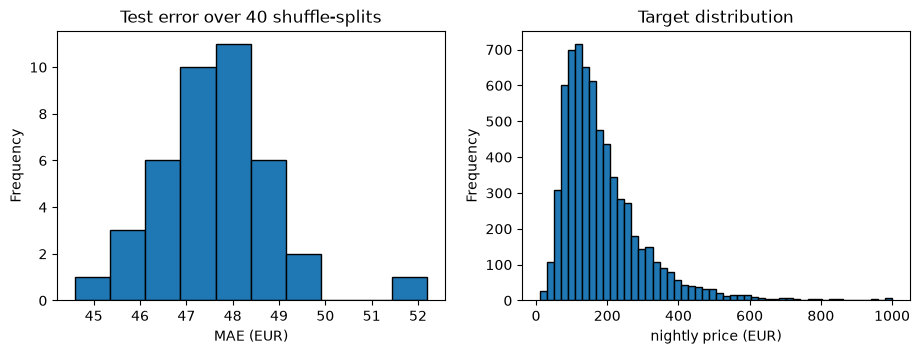

CV estimate: 47.6 +/- 1.3 EUR; standard deviation of the price: 117.3 EUR


In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
cv_results["test_error"].plot.hist(bins=10, edgecolor="black", ax=axes[0])
axes[0].set(xlabel="MAE (EUR)", title="Test error over 40 shuffle-splits")
price.plot.hist(bins=50, edgecolor="black", ax=axes[1])
axes[1].set(xlabel="nightly price (EUR)", title="Target distribution")
plt.show()
print(f"CV estimate: {cv_results['test_error'].mean():.1f} +/- {cv_results['test_error'].std():.1f} EUR;"
      f" standard deviation of the price: {price.std():.1f} EUR")

The cross-validated error is 47.6 ± 1.3 euros, small compared with the spread of prices (standard deviation 117.3 euros), but not small for a cheap room: an error of €47 is acceptable on a €400 flat and useless on a €40 room. A relative error (the log-scale error, or the mean absolute percentage error) can be the better metric when prices span two orders of magnitude.

> **Note.** The standard deviation of shuffle-split scores is not a valid standard error of the mean score: the randomly chosen training sets overlap, so the scores are correlated. It shows the variation caused by picking different random splits (ISLP Lab 5 makes the same point).

`cross_validate` can also return the fitted models with `return_estimator=True`, which lets you inspect the parameters learned in each split, and the training scores with `return_train_score=True` (section 3). When you only need the test scores, `cross_val_score` returns them as one array.

> 📖 **Read more:** [extras/02-train-test-and-cross-validation.ipynb](extras/02-train-test-and-cross-validation.ipynb) (INRIA scikit-learn MOOC): the same steps on the California housing data, with a decision tree.

## 3 · k-fold and stratified cross-validation

**Concept.** **k-fold cross-validation** divides the rows into *k* parts (**folds**) of roughly equal size. The model is trained *k* times, each time on *k* − 1 folds, and scored on the remaining fold. Unlike shuffle-split, **every row is used for validation exactly once**. The *k* scores are summarised by their mean (the estimate) and their standard deviation (how stable it is).

![Five-fold cross-validation (left): each row of blocks is one split; the orange block is the validation fold, the blue blocks are used for training. Time-series split (right): training always lies before validation.](../figures/cv_splits.png)

A small example by hand: 10 rows, *k* = 5. Fold 1 = rows 1–2, fold 2 = rows 3–4, and so on. In split 1 the model trains on rows 3–10 and is scored on rows 1–2; in split 2 it trains on rows 1–2 and 5–10 and is scored on rows 3–4. After five splits each row has been predicted once by a model that did not see it.

*The next two cells are adapted from "Stratification" ([INRIA scikit-learn MOOC](https://inria.github.io/scikit-learn-mooc/) (INRIA, CC BY 4.0)).*

Next we look at the indices that `KFold` produces on nine rows with three folds. `cv.split(data)` yields pairs of index arrays (training, test).

In [11]:
from sklearn.model_selection import KFold

data_random = np.random.default_rng(0).normal(size=(9, 1))
for train_index, test_index in KFold(n_splits=3).split(data_random):
    print("TRAIN:", train_index, "TEST:", test_index)

TRAIN: [3 4 5 6 7 8] TEST: [0 1 2]
TRAIN: [0 1 2 6 7 8] TEST: [3 4 5]
TRAIN: [0 1 2 3 4 5] TEST: [6 7 8]


`KFold` does **not shuffle by default**: the first three rows form the first test fold, and so on. That is fine for rows in random order and dangerous for sorted rows, as the depth section below shows. With `shuffle=True` the rows are shuffled once before they are cut into folds.

Next we cross-validate the price model with five shuffled folds. `cross_val_score(model, X, y, cv=..., scoring=...)` returns one score per fold. The `scoring` argument always expects a **score**, where higher is better, so error metrics come back as negative numbers: `eur = make_scorer(mae_eur, greater_is_better=False)` from section 0 wraps our euro MAE that way (built-in errors use a `neg_` prefix, such as `"neg_mean_absolute_error"`), and we flip the sign back.

In [12]:
from sklearn.model_selection import cross_val_score, cross_validate

kf = KFold(n_splits=5, shuffle=True, random_state=0)
fold_mae = -cross_val_score(gbm, X, y, cv=kf, scoring=eur)
print("MAE per fold EUR:", fold_mae.round(1))
print(f"mean {fold_mae.mean():.1f}, standard deviation {fold_mae.std():.1f}")

MAE per fold EUR: [47.3 46.7 47.2 47.9 47.1]
mean 47.3, standard deviation 0.4


Next we ask for several metrics at once and for the **training scores** as well. `cross_validate(..., scoring={name: scorer}, return_train_score=True)` returns `train_<name>` and `test_<name>` arrays. Comparing the two is the first diagnosis of overfitting (block 2 develops it into validation and learning curves).

In [13]:
res = cross_validate(gbm, X, y, cv=kf, return_train_score=True,
                     scoring={"mae_eur": eur, "r2": "r2"})
for m in ["mae_eur", "r2"]:
    sign = -1 if m == "mae_eur" else 1
    print(f"{m:8s} training {sign * res[f'train_{m}'].mean():.3f}   validation {sign * res[f'test_{m}'].mean():.3f}")

mae_eur  training 37.061   validation 47.254
r2       training 0.782   validation 0.636


The training error is clearly lower than the validation error: gradient boosting fits the training listings more closely than it can predict new ones. Some gap is normal; block 2 shows how to read its size.

> **Note.** In scikit-learn the validation scores of `cross_validate` are called `test_...`. They are validation scores in the sense of this notebook: they come from the development data, not from a locked test set.

### How many folds?

*k* = 5 or *k* = 10 are the usual choices. Each model is trained on (*k* − 1)/*k* of the data, so a small *k* trains on less data and its error estimate is slightly pessimistic (bias); a very large *k* trains *k* nearly identical models whose scores are highly correlated, which makes their average more variable, and it costs *k* fits. **Leave-one-out** cross-validation (LOOCV, *k* = *n*) is the extreme: almost unbiased, but *n* fits and a high-variance estimate. ISLP (James et al., 2023, section 5.1.4) recommends *k* = 5 or 10 as a good compromise. `cv=5` (an integer) is the scikit-learn default in `cross_val_score`, `cross_validate` and `GridSearchCV`.

### Stratified k-fold

**Concept.** For classification, **stratified k-fold** chooses the folds so that each has (almost) the same class proportions as the full data. This matters most for rare classes and small data: a fold without any positive case makes recall or ROC AUC undefined, and metrics such as precision depend on the share of positives.

The Telco churn table (Session 6) has 26.5 % churners. Next we download it and compare the churn share in the five validation folds of plain `KFold` and of `StratifiedKFold`. `skf.split(X, y)` needs the labels, because it stratifies on them.

In [14]:
from sklearn.model_selection import StratifiedKFold

URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
telco = pd.read_csv(URL)
churn = (telco["Churn"] == "Yes").astype(int)              # 1 = customer left
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
print("churn share overall:", round(churn.mean(), 3))
print("KFold:          ", [round(float(churn.iloc[va].mean()), 3) for _, va in kf.split(telco)])
print("StratifiedKFold:", [round(float(churn.iloc[va].mean()), 3) for _, va in skf.split(telco, churn)])

churn share overall: 0.265
KFold:           [0.261, 0.269, 0.289, 0.262, 0.246]
StratifiedKFold: [0.265, 0.265, 0.265, 0.265, 0.266]


Plain folds vary between 24.6 % and 28.9 % churners; stratified folds all hold 26.5 %. With 7,043 customers the difference is small; with 300 customers and 5 % positives it decides whether a fold has any positive case at all.

> **Note.** For a classifier, scikit-learn turns `cv=5` into `StratifiedKFold(5)` **without shuffling**; for a regressor into `KFold(5)`, also without shuffling. Pass a splitter object when you want shuffling and a fixed seed.

**In practice.**
- In genomics and medical imaging, where studies often have only a few hundred patients, k-fold cross-validation is the usual way to report performance.
- Credit scoring and churn teams typically compare candidate models by cross-validated ROC AUC before a final out-of-time test.

> **Note.** The *k* models of cross-validation are thrown away. Cross-validation estimates the performance of a *procedure* (this model type with these settings). To use the model, refit it on all development data.

### Sorted data and stratification *(depth: self-study or if time allows)*

*Adapted from "Stratification" ([INRIA scikit-learn MOOC](https://inria.github.io/scikit-learn-mooc/) (INRIA, CC BY 4.0)).*

The iris data (150 flowers, three species) are sorted by class: 50 rows of species 0, then 50 of species 1, then 50 of species 2. Next we cross-validate a logistic regression with unshuffled three-fold `KFold`. **Predict before running:** what accuracy will it reach on a toy problem where it usually exceeds 90 %?

In [15]:
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

iris_X, iris_y = load_iris(as_frame=True, return_X_y=True)
iris_model = make_pipeline(StandardScaler(), LogisticRegression())
for name, cv in [("KFold, no shuffle", KFold(3)), ("KFold, shuffle", KFold(3, shuffle=True, random_state=0)),
                 ("StratifiedKFold", StratifiedKFold(3))]:
    s = cross_validate(iris_model, iris_X, iris_y, cv=cv)["test_score"]
    print(f"{name:18s} accuracy {s.mean():.3f} +/- {s.std():.3f}")

KFold, no shuffle  accuracy 0.000 +/- 0.000
KFold, shuffle     accuracy 0.953 +/- 0.009
StratifiedKFold    accuracy 0.967 +/- 0.009


Without shuffling the model scores 0 % in every fold. Next we count the classes in each test fold to see why. `value_counts()` per fold, combined with `pd.concat(..., axis=1, keys=...)`, gives one column per fold.

In [16]:
def class_counts(cv):
    counts = [iris_y.iloc[te].value_counts() for _, te in cv.split(iris_X, iris_y)]
    return pd.concat(counts, axis=1, keys=[f"fold {i}" for i in range(len(counts))]).fillna(0).astype(int)


print("test folds of unshuffled KFold:\n", class_counts(KFold(3)))
print("\ntest folds of StratifiedKFold:\n", class_counts(StratifiedKFold(3)))

test folds of unshuffled KFold:
         fold 0  fold 1  fold 2
target                        
0           50       0       0
1            0      50       0
2            0       0      50

test folds of StratifiedKFold:
         fold 0  fold 1  fold 2
target                        
0           17      17      16
1           17      16      17
2           16      17      17


Each unshuffled test fold holds exactly the one species that is missing from its training folds, so the model is always asked to predict a class it never saw. Shuffling fixes this; stratification additionally keeps the class counts equal (here 16 or 17 of each species per fold).

One caveat from the scikit-learn user guide: stratification makes the folds more alike, which can make the fold-to-fold variability of a metric smaller than the true uncertainty, especially with severe class imbalance. Treat the standard deviation across stratified folds as a lower bound.

> 📖 **Read more:** [extras/03-stratified-cross-validation.ipynb](extras/03-stratified-cross-validation.ipynb) (INRIA scikit-learn MOOC): the same example with bar plots of the class counts in training and test folds.
>
> 📖 **Read more:** [extras/06-islp-resampling-lab.ipynb](extras/06-islp-resampling-lab.ipynb) (ISLP labs): the validation-set approach, LOOCV and 10-fold CV for choosing a polynomial degree on the `Auto` data; it needs the `ISLP` package.

## 4 · Grouped and time-series splits

**Concept.** k-fold assumes that rows are independent and that the future looks like a random sample of the past. Two common situations break this.

1. **Groups.** Several rows can belong to the same unit: several visits of the same patient, several transactions of the same customer, several listings of the same host. If a group appears in both training and validation folds, the model can recognise the group instead of learning a general pattern. **`GroupKFold`** (or `GroupShuffleSplit` for single splits) assigns whole groups to folds, so no group appears on both sides. It needs a `groups` array, here the host identifier.
2. **Time.** If the model will predict the future, a random split lets it train on rows recorded *after* the ones it is validated on. This hides changes over time (the COVID break in Berlin's tourism, a new registration rule), called **drift**. **`TimeSeriesSplit`** needs rows sorted by time: split *i* trains on the first part and validates on the block that follows.

```mermaid
flowchart TD
    Q1{"Will the model be used<br/>on new groups?<br/>(new hosts, patients)"} -->|yes| G["GroupKFold"]
    Q1 -->|no| Q2{"Will it predict<br/>the future?"}
    Q2 -->|yes| TS["TimeSeriesSplit or<br/>one out-of-time split"]
    Q2 -->|no| Q3{"Classification?"}
    Q3 -->|yes| S["StratifiedKFold"]
    Q3 -->|no| K["KFold (shuffle=True)"]
```

**Why it matters.** The splitter must reproduce the situation in which the model will be used. Ordinary k-fold measures performance on groups and periods already seen; the real use often involves new ones. A price suggestion is most useful for a host who has never listed before, and a forecast is always about next month.

### Groups: the same host on both sides

Many hosts offer several similar flats, often in the same building, at similar prices. Next we measure how common that is. `hosts.map(hosts.value_counts())` gives each listing the number of listings of its host.

In [17]:
n_per_host = hosts.map(hosts.value_counts())
print("share of listings whose host has several:", round((n_per_host > 1).mean(), 3),
      "; largest host:", n_per_host.max(), "listings")

share of listings whose host has several: 0.565 ; largest host: 83 listings


**Predict before running:** will host-grouped folds report a larger or a smaller error than random folds, and by how much?

Next we cross-validate with `GroupKFold(5)`. The host of each row is passed with `groups=hosts`; the splitter puts all listings of a host into the same fold.

In [18]:
from sklearn.model_selection import GroupKFold

grouped = -cross_val_score(gbm, X, y, cv=GroupKFold(5), groups=hosts, scoring=eur)
print(f"random folds:       MAE EUR {fold_mae.mean():.1f} (sd {fold_mae.std():.1f})")
print(f"host-grouped folds: MAE EUR {grouped.mean():.1f} (sd {grouped.std():.1f})")

random folds:       MAE EUR 47.3 (sd 0.4)
host-grouped folds: MAE EUR 49.9 (sd 3.0)


Host-grouped folds report a larger error (49.9 against 47.3 euros) and a larger spread: in a random split, more than half of the validation listings have a host whose other flats sit in the training folds, and the model partly recognises "a flat of this host". Which number is right depends on the use. A price suggestion for a **new host** must be judged with `GroupKFold`; a tool that only prices further flats of hosts already in the data may use the random estimate. Section 8 shows that the gap becomes much larger as soon as a feature describes the host.

> **Note.** `StratifiedGroupKFold` combines both constraints: whole groups per fold and class shares as equal as the groups allow.

### Seeing what the splitters do *(depth: self-study or if time allows)*

*Adapted from "Visualizing cross-validation behavior in scikit-learn" ([scikit-learn gallery](https://scikit-learn.org/stable/auto_examples/model_selection/plot_cv_indices.html), the scikit-learn developers, BSD-3-Clause).*

A picture of the indices makes the differences obvious. The data are 100 synthetic rows with three classes of unequal size (10 %, 30 %, 60 %) and ten groups of unequal size, in sorted order. Next we define the gallery's plotting function: for each split it colours the training rows blue and the test rows red, and below the splits it shows the class and the group of every row.

In [19]:
from matplotlib.patches import Patch
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, TimeSeriesSplit

rng = np.random.RandomState(1338)
X_toy = rng.randn(100, 10)
y_toy = np.hstack([[ii] * int(100 * perc) for ii, perc in enumerate([0.1, 0.3, 0.6])])
groups_toy = np.repeat(np.arange(10), rng.multinomial(100, rng.dirichlet([2] * 10)))
cmap_data, cmap_cv = plt.cm.Paired, plt.cm.coolwarm

In [20]:
def plot_cv_indices(cv, X, y, group, ax, n_splits, lw=10):
    use_groups = "Group" in type(cv).__name__
    for ii, (tr, tt) in enumerate(cv.split(X=X, y=y, groups=group if use_groups else None)):
        indices = np.array([np.nan] * len(X))
        indices[tt], indices[tr] = 1, 0
        ax.scatter(range(len(indices)), [ii + 0.5] * len(indices), c=indices, marker="_", lw=lw,
                   cmap=cmap_cv, vmin=-0.2, vmax=1.2)
    ax.scatter(range(len(X)), [ii + 1.5] * len(X), c=y, marker="_", lw=lw, cmap=cmap_data)
    ax.scatter(range(len(X)), [ii + 2.5] * len(X), c=group, marker="_", lw=lw, cmap=cmap_data)
    ax.set(yticks=np.arange(n_splits + 2) + 0.5, yticklabels=list(range(n_splits)) + ["class", "group"],
           xlabel="Sample index", ylabel="CV iteration", ylim=[n_splits + 2.2, -0.2], xlim=[0, 100])
    ax.set_title(type(cv).__name__, fontsize=11)

Next we draw six splitters side by side, each with four splits.

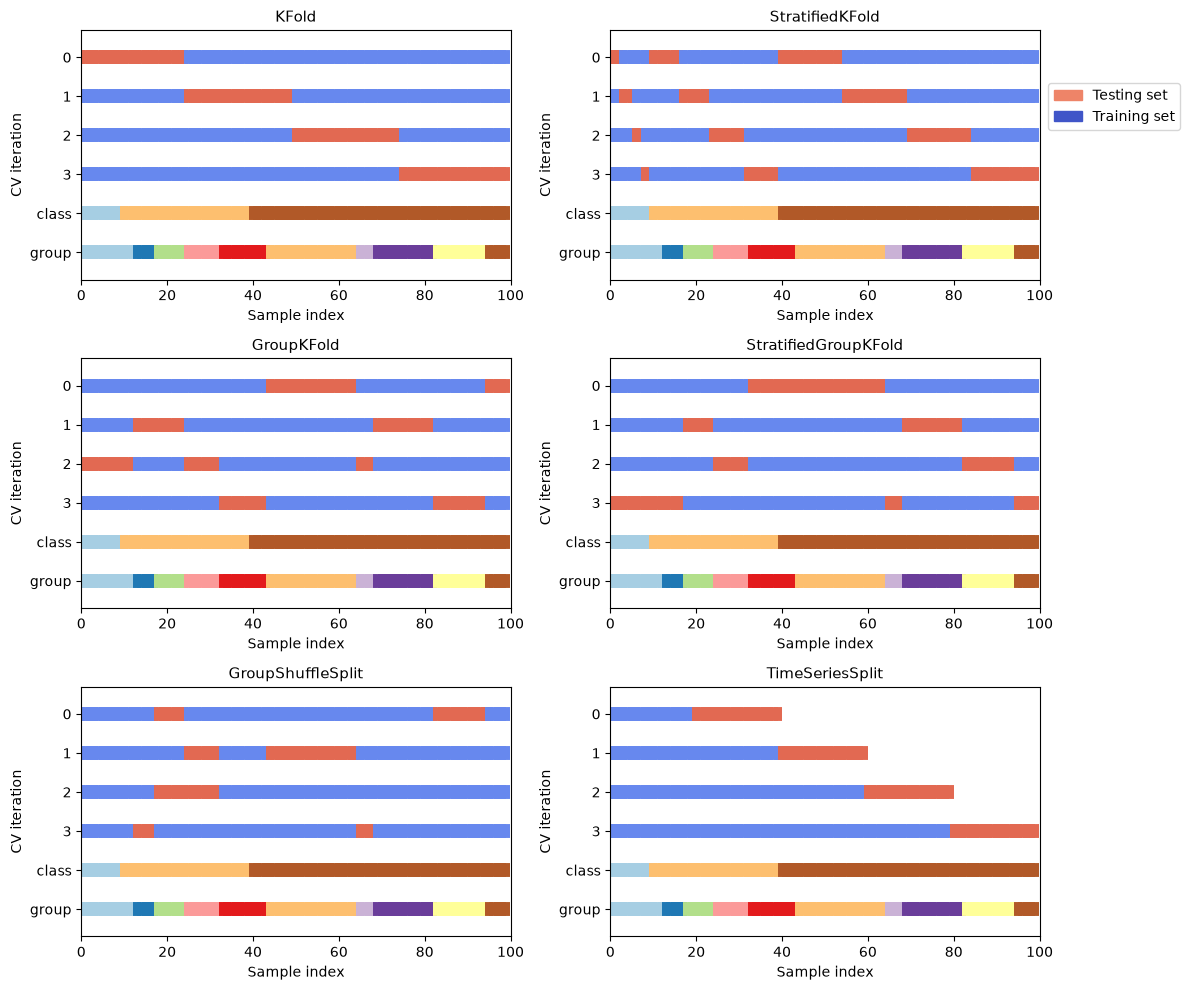

In [21]:
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
for ax, cv in zip(axes.ravel(), [KFold(4), StratifiedKFold(4), GroupKFold(4), StratifiedGroupKFold(4),
                                 GroupShuffleSplit(4, random_state=0), TimeSeriesSplit(4)]):
    plot_cv_indices(cv, X_toy, y_toy, groups_toy, ax, 4)
axes[0, 1].legend([Patch(color=cmap_cv(0.8)), Patch(color=cmap_cv(0.02))], ["Testing set", "Training set"],
                  loc=(1.02, 0.6))
plt.tight_layout()
plt.show()

How to read it: `KFold` ignores classes and groups and cuts the sorted rows into blocks, so the first test fold holds only the rare class. `StratifiedKFold` takes rows from every class into every fold. `GroupKFold` never splits a group (a colour in the bottom bar) between training and test. `StratifiedGroupKFold` keeps groups whole and balances the classes as far as the groups allow. `GroupShuffleSplit` draws random groups for each test set, so groups can be tested more than once or never. `TimeSeriesSplit` always tests on the rows right after the training rows, and the training window grows.

> 📖 **Read more:** [extras/05-cross-validation-splitters.ipynb](extras/05-cross-validation-splitters.ipynb) (scikit-learn gallery): the full example, including `ShuffleSplit` and `StratifiedShuffleSplit`.

### Groups you cannot see: handwritten digits *(depth: self-study or if time allows)*

*Adapted from "Sample grouping" ([INRIA scikit-learn MOOC](https://inria.github.io/scikit-learn-mooc/) (INRIA, CC BY 4.0)).*

Groups are not always labelled. The `load_digits` data are 1,797 small images of handwritten digits written by about 13 people, stored roughly writer by writer. Each person writes a digit in a personal way. Next we compare unshuffled `KFold` (which keeps most of each writer's digits together), shuffled `KFold` (which spreads every writer over all folds) and `GroupKFold` with writer groups reconstructed from the row order. The boundaries come from the INRIA notebook, which found 14 blocks of about 130 rows that each start with the digits 0 to 9 in order.

In [22]:
from sklearn.datasets import load_digits
from sklearn.preprocessing import MinMaxScaler

digits = load_digits()
digit_model = make_pipeline(MinMaxScaler(), LogisticRegression(max_iter=1_000))
bounds = [0, 130, 256, 386, 516, 646, 776, 915, 1029, 1157, 1287, 1415, 1545, 1667, 1797]
writer = np.repeat(np.arange(len(bounds) - 1), np.diff(bounds))
for name, cv, g in [("KFold, no shuffle", KFold(5), None),
                    ("KFold, shuffle", KFold(5, shuffle=True, random_state=0), None),
                    ("GroupKFold by writer", GroupKFold(5), writer)]:
    s = cross_val_score(digit_model, digits.data, digits.target, cv=cv, groups=g)
    print(f"{name:21s} accuracy {s.mean():.3f} +/- {s.std():.3f}")

KFold, no shuffle     accuracy 0.931 +/- 0.027
KFold, shuffle        accuracy 0.968 +/- 0.008
GroupKFold by writer  accuracy 0.921 +/- 0.021


Shuffling lets the model see each writer's style during training, so it scores higher; grouping by writer gives the lower, honest estimate for **new writers**. The Airbnb hosts are the same situation with an explicit `host_id`. (`MinMaxScaler` is used because pixel values are bounded between 0 and 16 and some border pixels are almost always 0, where a `StandardScaler` would divide by a tiny standard deviation.)

> 📖 **Read more:** [extras/04-grouped-cross-validation.ipynb](extras/04-grouped-cross-validation.ipynb) (INRIA scikit-learn MOOC): the same example with histograms of the fold scores and a plot of the writer groups.
>
> 📖 **Read more:** [extras/08-honest-validation-practice.ipynb](extras/08-honest-validation-practice.ipynb) (course notebook): six synthetic listings, small enough to follow by hand, show that a random split and an unseen-host split answer different questions.

### Time: `TimeSeriesSplit`

The listings snapshot is a single day and has no time order to respect. To see the scheme, next we split twelve months with `TimeSeriesSplit(n_splits=4, test_size=2)`. `pd.period_range` creates a sequence of months.

In [23]:
from sklearn.model_selection import TimeSeriesSplit

months = pd.period_range("2025-07", periods=12, freq="M")
for tr, va in TimeSeriesSplit(n_splits=4, test_size=2).split(months):
    print(f"train {months[tr[0]]} to {months[tr[-1]]}   validate {months[va[0]]} to {months[va[-1]]}")

train 2025-07 to 2025-10   validate 2025-11 to 2025-12
train 2025-07 to 2025-12   validate 2026-01 to 2026-02
train 2025-07 to 2026-02   validate 2026-03 to 2026-04
train 2025-07 to 2026-04   validate 2026-05 to 2026-06


Every validation block lies after its training block, and the training window grows (an **expanding window**). Three parameters change the scheme:

- `test_size`: the length of each validation block;
- `max_train_size`: caps the training window, which then **rolls** forward (useful when old data are no longer representative);
- `gap`: leaves out rows between training and validation, for example when a feature uses information that only arrives a month later, or when the forecast is made for two months ahead.

Next we combine a rolling window of six months with a gap of one month.

In [24]:
for tr, va in TimeSeriesSplit(n_splits=3, test_size=2, max_train_size=6, gap=1).split(months):
    print(f"train {months[tr[0]]} to {months[tr[-1]]}   gap   validate {months[va[0]]} to {months[va[-1]]}")

train 2025-07 to 2025-11   gap   validate 2026-01 to 2026-02
train 2025-08 to 2026-01   gap   validate 2026-03 to 2026-04
train 2025-10 to 2026-03   gap   validate 2026-05 to 2026-06


### Why shuffled folds flatter a forecast *(depth: self-study or if time allows)*

The Airbnb data do contain a time series: the number of reviews written in Berlin each month, a rough measure of how many stays took place. Next we build a small forecasting table from `reviews_monthly.parquet` (one row per listing and month): city-wide reviews per month from January 2015 to May 2026 (the first twelve months only serve as lags), the log of the count as target, and two kinds of features. The first kind describes the calendar: `t` counts the months since the start, `month` is the month of the year. The second kind are **lags**: the log counts one, two and twelve months earlier. `shift(k)` moves a column down by *k* rows, so each month sees only earlier months.

In [25]:
monthly = (pd.read_parquet("case-study/data/airbnb/reviews_monthly.parquet")
           .groupby("month")["n_reviews"].sum().loc["2015-01-01":"2026-05-01"])
ts = pd.DataFrame({"y": np.log(monthly)})
ts["t"], ts["month"] = np.arange(len(ts)), ts.index.month
for k in [1, 2, 12]:
    ts[f"lag{k}"] = ts["y"].shift(k)
ts = ts.dropna()
print(len(ts), "months from", ts.index.min().date(), "to", ts.index.max().date())

125 months from 2016-01-01 to 2026-05-01


**Predict before running:** a random forest learns the level of each period from `t` and the season from `month`. Which splitter will report the smaller error?

Next we cross-validate two models twice, with shuffled 5-fold CV and with a `TimeSeriesSplit` that always forecasts the following twelve months: the random forest on the calendar features, and a linear regression on the lags. The error is the mean absolute error on the log scale × 100, roughly a percentage of the monthly count.

In [26]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

models = {"forest on t, month": (RandomForestRegressor(200, random_state=0), ["t", "month"]),
          "linear on lags":     (LinearRegression(), ["lag1", "lag2", "lag12"])}
for name, (model, feats) in models.items():
    for cv_name, cv in [("shuffled KFold", KFold(5, shuffle=True, random_state=0)),
                        ("TimeSeriesSplit", TimeSeriesSplit(n_splits=5, test_size=12))]:
        s = -cross_val_score(model, ts[feats], ts["y"], cv=cv, scoring="neg_mean_absolute_error")
        print(f"{name:19s} {cv_name:16s} error about {100 * s.mean():.0f} %")

forest on t, month  shuffled KFold   error about 13 %


forest on t, month  TimeSeriesSplit  error about 33 %
linear on lags      shuffled KFold   error about 17 %
linear on lags      TimeSeriesSplit  error about 16 %


For the forest, shuffled folds report an error of 13 % and time-ordered folds 33 %. With shuffled folds the model "forecasts" March 2020 from a training set that contains February and April 2020, so it only has to interpolate; forecasting means extrapolating into months it has never seen, including the COVID collapse. The lag model barely changes (17 % against 16 %), because its features always carry the most recent level. So the size of the optimism depends on the model, but only the time-ordered folds tell you which situation you are in. Session 12 builds on this scheme (rolling-origin evaluation) for the demand forecast.

**In practice.**
- Medical imaging: the CheXNet study (Rajpurkar et al., 2017) split the ChestX-ray14 images by patient so that no patient appeared in both training and test data.
- Credit risk models in banks are routinely validated out-of-time: trained on older loans and tested on more recent ones.
- Demand and energy-load forecasting use rolling-origin evaluation, the forecasting name for `TimeSeriesSplit` (Session 12).

> **Note.** `TimeSeriesSplit` uses the row order. Sort by date first (`sort_values("date", ignore_index=True)`); otherwise "past" and "future" are arbitrary.

> **Note.** Grouping and time can both apply. A model for next year's prices of *new* hosts needs both: hosts kept together and the latest period held out. Decide which situation matters for your project and say so in the validation plan.

## 5 · Bootstrap confidence interval of a metric

**Concept.** The **bootstrap** (Efron, 1979; recap in Session 5) estimates the uncertainty of a statistic from a single sample: draw *n* rows **with replacement** from the *n* rows, recompute the statistic, and repeat about 1,000 times. The spread of the recomputed values approximates the sampling variability. For a model's test score, the model and its predictions stay fixed and only the test rows are resampled. The 2.5 % and 97.5 % percentiles of the bootstrap values form a 95 % **percentile confidence interval**.

A tiny example by hand. Five test listings with absolute price errors of €10, €20, €30, €40 and €100: the MAE is €40. One bootstrap sample draws positions 2, 2, 3, 5, 1, giving €20, €20, €30, €100, €10 and an MAE of €36; another draws 5, 5, 4, 1, 5, giving €100, €100, €40, €10, €100 and €70. Repeating this many times gives a distribution of MAEs; with only five rows it is very wide, which is the honest answer.

**Why it matters.** A score without an interval cannot tell whether a difference between two models, or between a validation score and a later test score, is larger than chance. The bootstrap works for any metric (MAE in euros, macro-F1, ROC AUC), including those for which no simple formula exists.

The practice question: lock away 20 % of the **hosts** with all their listings, fit the model on the other hosts, and compute the MAE in euros on the locked hosts. `GroupShuffleSplit(n_splits=1, test_size=0.2)` makes one host-grouped split; `next(...)` takes it out of the generator.

In [27]:
from sklearn.model_selection import GroupShuffleSplit

dev, test = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0).split(X, y, groups=hosts))
gbm.fit(X.iloc[dev], y.iloc[dev])                          # trained on 80 % of the hosts
abs_err = np.abs(price.iloc[test].to_numpy() - np.exp(gbm.predict(X.iloc[test])))
print(len(test), "test listings of", hosts.iloc[test].nunique(), "hosts")
print(f"MAE EUR {abs_err.mean():.1f}; median price of the test listings EUR {price.iloc[test].median():.0f}")

1254 test listings of 748 hosts
MAE EUR 50.8; median price of the test listings EUR 160


*The next cell is adapted from ISLP Lab 5 ([ISLP labs](https://github.com/intro-stat-learning/ISLP_labs), BSD-2-Clause), which writes its own bootstrap function.*

Next we write a general bootstrap function. `rng.integers(0, n, n)` draws *n* positions with replacement; `func(values[idx])` recomputes the statistic on the resampled rows. The loop variable `_` signals that the counter itself is not used.

In [28]:
def bootstrap(values, func=np.mean, B=1000, seed=0):
    # Recompute func on B resamples (with replacement) of values.
    rng = np.random.default_rng(seed)
    n = len(values)
    return np.array([func(values[rng.integers(0, n, n)]) for _ in range(B)])


boot_rows = bootstrap(abs_err)
print("bootstrap standard error EUR:", round(boot_rows.std(), 2))
print("95 % interval, listings resampled:", np.percentile(boot_rows, [2.5, 97.5]).round(1))

bootstrap standard error EUR: 1.87
95 % interval, listings resampled: [47.4 54.8]


That interval treats the 1,254 test listings as independent. They are not: they come from 748 hosts, and a host's listings tend to be all well or all badly priced by the model. A **cluster bootstrap** resamples whole hosts instead. Next we sum the errors and count the listings per host, draw hosts with replacement and divide the summed errors by the summed counts. `pd.Series.groupby(...).sum()` and `.size()` give one value per host.

In [29]:
by_host = pd.Series(abs_err).groupby(hosts.iloc[test].to_numpy())
sums, counts = by_host.sum().to_numpy(), by_host.size().to_numpy()
rng = np.random.default_rng(0)
boot_hosts = []
for _ in range(1000):
    pick = rng.integers(0, len(sums), len(sums))           # draw whole hosts with replacement
    boot_hosts.append(sums[pick].sum() / counts[pick].sum())
print("95 % interval, hosts resampled:   ", np.percentile(boot_hosts, [2.5, 97.5]).round(1))

95 % interval, hosts resampled:    [45.3 56.5]


Next we draw both bootstrap distributions on one axis, so the difference in width is visible.

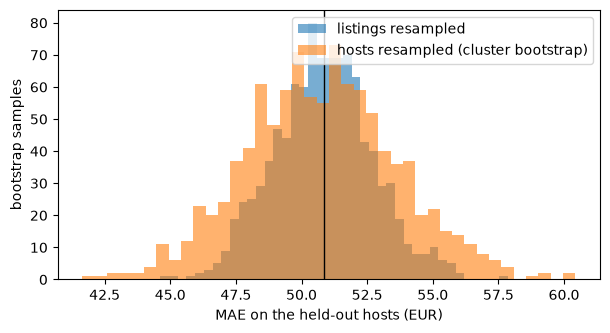

In [30]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(boot_rows, bins=40, alpha=0.6, label="listings resampled")
ax.hist(boot_hosts, bins=40, alpha=0.6, label="hosts resampled (cluster bootstrap)")
ax.axvline(abs_err.mean(), color="black", lw=1)
ax.set(xlabel="MAE on the held-out hosts (EUR)", ylabel="bootstrap samples")
ax.legend()
plt.show()

For a new host the model is off by about 51 euros a night on average, with a 95 % interval of roughly 45 to 57 euros: about a third of the median price. The listing bootstrap is narrower because it pretends to have more independent information than there is. A model that reaches €49 instead of €51 on this test set is not demonstrably better.

**Percentile or standard-error interval?** A second common recipe is *estimate ± 1.96 × bootstrap standard error*. It assumes a roughly normal bootstrap distribution; the percentile interval does not, and is the usual choice for metrics such as MAE or AUC.

> **Note.** Two related summaries are easy to confuse. The **standard deviation across CV folds** describes how much the score varies between training sets and validation folds. The **bootstrap interval on a test set** describes the uncertainty from the finite test sample for one fitted model. Both are useful; say which one you report.

> **Note.** Resample the *test rows*, not the training rows, when you want the uncertainty of a test score. Refitting the model inside every bootstrap round answers a different question (the variability of the training procedure) and is far slower.

**In practice.**
- Diagnostic accuracy studies in medicine report sensitivity, specificity and AUC with 95 % confidence intervals; bootstrap intervals are common for AUC.
- Machine translation research uses paired bootstrap resampling (Koehn, 2004) to test whether one system's BLEU score beats another's on the same test set.

> 📖 **Read more:** [extras/06-islp-resampling-lab.ipynb](extras/06-islp-resampling-lab.ipynb) (ISLP labs): the bootstrap standard error of a portfolio statistic and of regression coefficients, compared with the textbook formulas.
>
> 📖 **Read more:** [extras/07-bootstrap-and-simulation.ipynb](extras/07-bootstrap-and-simulation.ipynb) (Statistical Thinking for the 21st Century, CC BY-NC 4.0): simulates a sampling distribution and checks that the bootstrap distribution of the mean matches the theoretical one.
>
> 📖 **Read more:** [extras/20-case-study-churn-validation.ipynb](extras/20-case-study-churn-validation.ipynb) (course notebook): part A reports the cross-validated ROC AUC of the Telco churn model with a bootstrap 95 % interval.

## 6 · Data leakage: preprocessing outside the cross-validation

**Concept.** **Data leakage** means that information from the validation or test rows, or information that will not exist at prediction time, slips into training. The result is a score that is too good to be true, and a model that disappoints in use.

The first form is preprocessing outside the cross-validation. Many preparation steps *learn* from the data: a `StandardScaler` learns means and standard deviations, a `SimpleImputer` learns medians, a feature selector learns which columns are related to the target, a `TargetEncoder` learns the mean target of each category. If such a step is fitted on **all** rows before the data are split, the validation folds have influenced training.

How much this matters depends on the step. Scaling with the overall mean instead of the training mean changes little when the data are large. A step that looks at the **target** can change the result completely.

**Why it matters.** Kapoor and Narayanan (2023) reviewed studies in 17 scientific fields and found leakage in hundreds of papers, often with strongly over-optimistic claims.

### The extreme case: feature selection on pure noise

*Adapted from "Feature selection: solution for exercise 01" ([INRIA scikit-learn MOOC](https://inria.github.io/scikit-learn-mooc/) (INRIA, CC BY 4.0)).*

Next we create a data set with 100 rows, 10,000 columns of random numbers and a random 0/1 target. No model can do better than 50 % accuracy. Then we choose the 10 columns with the highest ANOVA F-score (`SelectKBest(f_classif, k=10)`) **on all rows**, and cross-validate a logistic regression on them. **Predict before running:** what accuracy will cross-validation report?

In [31]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

rng = np.random.RandomState(42)
noise, coin = rng.randn(100, 10_000), rng.randint(0, 2, size=100)
print(f"all 10,000 columns:          accuracy {cross_val_score(LogisticRegression(), noise, coin).mean():.2f}")

noise_sel = SelectKBest(f_classif, k=10).fit_transform(noise, coin)       # WRONG: selection sees all rows
print(f"10 columns chosen on all rows: accuracy {cross_val_score(LogisticRegression(), noise_sel, coin).mean():.2f}")

all 10,000 columns:          accuracy 0.34
10 columns chosen on all rows: accuracy 0.85


Among 10,000 random columns, some are correlated with the labels *in these 100 rows* by chance. Selected on all rows, those chance correlations are present in every validation fold too, because the validation rows helped to pick them. The fix is to make the selector part of the model, so that it is refitted on the training folds only. `make_pipeline(step1, step2)` chains a transformer and a model into one estimator.

In [32]:
leak_free = make_pipeline(SelectKBest(f_classif, k=10), LogisticRegression())
print(f"selection inside each training fold: accuracy {cross_val_score(leak_free, noise, coin).mean():.2f}")

selection inside each training fold: accuracy 0.47


Back to chance level, as it must be. The same mistake on a single split is fixed by fitting the selector on the training part and only *applying* it (`transform`) to the test part; with cross-validation or tuning, a pipeline does this for every fold automatically (section 8).

> 📖 **Read more:** [extras/09-data-leakage-feature-selection.ipynb](extras/09-data-leakage-feature-selection.ipynb) (INRIA scikit-learn MOOC): the same exercise with a manual train-test split before the pipeline.

### The same mistake on the price model

A tempting feature: "listings in an expensive neighbourhood are expensive", so add the **mean log price of the neighbourhood** (138 Ortsteile). Computed with `groupby(...).transform("mean")` on all listings, every listing's own price has gone into the mean of its neighbourhood. Next we compare that with the same idea learned properly: `TargetEncoder` replaces each neighbourhood by its mean target, learned on the training folds only (and cross-fitted within them; Session 9 explains how). `make_column_transformer((encoder, columns), remainder="passthrough")` applies the encoder to the listed columns and passes the others through.

In [33]:
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import TargetEncoder

X_nb = X.assign(nb_price=y.groupby(bnb["neighbourhood"]).transform("mean"))   # uses every listing's own price
print(f"neighbourhood mean from all rows:  MAE EUR {-cross_val_score(gbm, X_nb, y, cv=kf, scoring=eur).mean():.1f}")

X_raw = X.assign(neighbourhood=bnb["neighbourhood"], host=hosts.astype(str))
te_nb = make_column_transformer((TargetEncoder(cv=KFold(5, shuffle=True, random_state=0)), ["neighbourhood"]),
                                remainder="passthrough")
nb_pipe = make_pipeline(te_nb, HistGradientBoostingRegressor(random_state=0))
print(f"neighbourhood mean inside the CV:  MAE EUR {-cross_val_score(nb_pipe, X_raw.drop(columns='host'), y, cv=kf, scoring=eur).mean():.1f}")

neighbourhood mean from all rows:  MAE EUR 46.6


neighbourhood mean inside the CV:  MAE EUR 46.9


With about 50 listings per neighbourhood one listing moves its neighbourhood mean only a little, so the leak is small here (46.6 against 46.9 euros). The next section shows the same mistake where the groups are small.

> **Note.** Any step that looks at the target (feature selection by correlation with y, target encoding, resampling such as SMOTE in Session 8) must be fitted inside the cross-validation. Fitted on all rows, it produces scores that cannot be trusted at all.

**In practice.**
- Kapoor and Narayanan (2023) traced a series of over-optimistic results in civil-war prediction to leakage, including imputation fitted on the full data set; after correction, the complex models did not beat a logistic regression.
- The scikit-learn user guide page "Common pitfalls and recommended practices" opens with preprocessing outside the cross-validation, using the same feature-selection example.

## 7 · Data leakage: target leakage

**Concept.** **Target leakage** means that a feature contains information about the target that will not be available when the model is used. Typical sources:

- a feature *computed from the target*, for example a seller's average rating that includes the rating being predicted;
- a feature *recorded after the event*, for example "reason for cancellation" in a churn table, or "antibiotic prescribed" when predicting an infection;
- an identifier or timestamp that happens to correlate with the label in the collected data.

The model learns the shortcut, cross-validation confirms it (the shortcut is present in every fold), and the model fails in use, where the shortcut is missing.

**Why it matters.** No splitter can detect target leakage: the leak is inside the rows. It can only be found by asking, for every feature, *"would I know this value at the moment of prediction?"*

A tempting feature for the price model is the **host's average price**: hosts with expensive flats tend to have more expensive flats. Computed from all listings, it contains the listing's own price. For hosts with a single listing the "host average" *is* the target, and a first-time host has no average at all. Next we add it and cross-validate with random and with host-grouped folds.

In [34]:
X_host = X_nb.assign(host_price=y.groupby(hosts).transform("mean"))
print("share of listings whose host has only this listing:", round((n_per_host == 1).mean(), 3))
for label, cv, g in [("random folds", kf, None), ("host-grouped folds", GroupKFold(5), hosts)]:
    s = -cross_val_score(gbm, X_host, y, cv=cv, groups=g, scoring=eur)
    print(f"host mean from all rows, {label}: MAE EUR {s.mean():.1f}")

share of listings whose host has only this listing: 0.435


host mean from all rows, random folds: MAE EUR 26.6


host mean from all rows, host-grouped folds: MAE EUR 28.0


Cross-validation now promises an error of 27 to 28 euros instead of about 47, and host-grouped folds do not help: the leak sits inside each row and travels with it into whichever fold it lands in. One new feature that nearly halves the error is a warning sign. Session 9 meets a second case in the same table: the `estimated_revenue_l365d` column of Inside Airbnb is computed from the price.

**In practice.**
- KDD Cup 2008 (breast cancer detection): the patient identifier was predictive of the label because of how the data had been assembled; Kaufman et al. (2012) use it as a textbook case of leakage.
- Hospital data: "chest X-ray ordered" can reveal the diagnosis a model is supposed to predict, because it is recorded after the doctor suspected it.
- Churn data: fields like "reason for leaving" are filled only for customers who have already left.

> **Note.** A suspiciously large jump in validation score from one new feature is a warning sign, not a success. Check when and how that feature is recorded before you celebrate.

## 8 · Preprocessing inside a Pipeline

**Concept.** A scikit-learn **`Pipeline`** chains steps: zero or more transformers (imputer, scaler, encoder, selector) and a final model. Calling `fit` on the pipeline fits each step on the training data and passes the transformed data on; calling `predict` or `score` only *applies* the fitted steps to new data. When a pipeline is passed to `cross_val_score`, `cross_validate` or `GridSearchCV`, the **whole pipeline** is refitted on the training folds of every split, so the validation fold never influences any step.

```mermaid
sequenceDiagram
    participant CV as cross_val_score
    participant P as Pipeline
    participant Tr as Training folds
    participant Va as Validation fold
    CV->>P: fit(training folds)
    P->>Tr: encoder learns category means
    P->>Tr: model learns its parameters
    CV->>P: score(validation fold)
    P->>Va: apply stored means
    P->>Va: predict and score
```

**Why it matters.** The pipeline turns "remember to fit the encoder only on the training part" from a rule that people forget into code that cannot get it wrong. It also packages preparation and model into one object that can be saved and deployed (Session 16), so the same steps are applied to new data in production. Session 8 extends it with `ColumnTransformer` for mixed columns.

Next we put a `TargetEncoder` for the neighbourhood **and** the host into the pipeline. `make_pipeline` names the steps automatically (lower-case class names), which is how a search addresses their settings in block 2.

In [35]:
encode = make_column_transformer((TargetEncoder(cv=KFold(5, shuffle=True, random_state=0)), ["neighbourhood", "host"]),
                                 remainder="passthrough")
pipe = make_pipeline(encode, HistGradientBoostingRegressor(random_state=0))
print(list(pipe.named_steps))

['columntransformer', 'histgradientboostingregressor']


**Predict before running:** the encoder now learns the host means from the training folds only. Will random folds and host-grouped folds give the same error?

In [36]:
pipe_cv = {}
for label, cv, g in [("random folds", kf, None), ("host-grouped folds", GroupKFold(5), hosts)]:
    pipe_cv[label] = -cross_val_score(pipe, X_raw, y, cv=cv, groups=g, scoring=eur).mean()
    print(f"TargetEncoder inside the pipeline, {label}: MAE EUR {pipe_cv[label]:.1f}")

TargetEncoder inside the pipeline, random folds: MAE EUR 44.2


TargetEncoder inside the pipeline, host-grouped folds: MAE EUR 50.4


The pipeline removes most of the leak. But with random folds the error is still the lowest of all honest-looking numbers (44.2 euros): more than half of the validation listings have a host whose other listings sit in the training folds, so the encoder knows that host's prices. That is the **second leaking workflow: the same host in training and validation**. A first-time host is never in the training data, and only host-grouped folds (50.4 euros) reproduce that. Each leak needs its own fix: the pipeline removes the target from the features, the grouped folds remove the host's other listings from training.

> **Note.** If a step needs the target or learns anything from the data (medians, means, categories, a vocabulary), it belongs in the pipeline. If it is a fixed rule that looks at one row at a time (the distance to Alexanderplatz from the coordinates, `np.log` of the price), it can be applied before splitting.

### What `cross_val_score` does with a pipeline *(depth: self-study or if time allows)*

To see that nothing magic happens, next we write the cross-validation loop by hand. `clone(pipe)` makes an unfitted copy with the same settings, so no information carries over from one fold to the next.

In [37]:
from sklearn.base import clone

fold_errors = []
for tr, va in GroupKFold(5).split(X_raw, y, groups=hosts):
    fold_model = clone(pipe).fit(X_raw.iloc[tr], y.iloc[tr])           # encoder and model see training folds only
    fold_errors.append(mae_eur(y.iloc[va], fold_model.predict(X_raw.iloc[va])))
print("MAE per fold EUR:", np.round(fold_errors, 1), " mean", round(np.mean(fold_errors), 1))

MAE per fold EUR: [54.2 46.5 54.7 47.8 48.5]  mean 50.4


The mean equals the host-grouped result above. Doing the same with a manual `fit_transform` on the training part and `transform` on the validation part is correct for one split, but breaks as soon as you cross-validate or tune: you would have to repeat it by hand for every fold. Use a pipeline.

**In practice.**
- Production systems serialise the fitted pipeline (for example with `joblib` or `skops`) rather than the model alone, so that serving code cannot apply different preprocessing; "training–serving skew" is a known source of failures described in Google's *Rules of Machine Learning* (Zinkevich).
- The INRIA scikit-learn MOOC uses pipelines from its first module onwards for exactly this reason.

## 9 · Worked example · Which validation promise comes true for new hosts?

The decisive check: lock away 20 % of the hosts (the split of section 5), fit each workflow on the other hosts, and predict the locked-away listings the way the model would be used. A new host has no price history, so the host mean is missing; the neighbourhood means come from the development hosts only.

Next we build the leaky workflow's columns honestly for this check: means from the development hosts, `NaN` for the host mean of every new host. `Series.map(other_series)` looks up each neighbourhood's development mean.

In [38]:
X_d, y_d, X_new = X_raw.iloc[dev], y.iloc[dev], X_raw.iloc[test]
leaky_d = X_d.drop(columns=["neighbourhood", "host"]).assign(
    nb_price=y_d.groupby(X_d["neighbourhood"]).transform("mean"),
    host_price=y_d.groupby(X_d["host"]).transform("mean"))
leaky_new = X_new.drop(columns=["neighbourhood", "host"]).assign(
    nb_price=X_new["neighbourhood"].map(y_d.groupby(X_d["neighbourhood"]).mean()),
    host_price=np.nan)                                        # a new host has no price history

Next we fit both workflows on the development hosts and score them once on the new hosts.

In [39]:
leaky_model = HistGradientBoostingRegressor(random_state=0).fit(leaky_d, y_d)
new_leaky = mae_eur(y.iloc[test], leaky_model.predict(leaky_new))
new_pipe = mae_eur(y.iloc[test], clone(pipe).fit(X_d, y_d).predict(X_new))
print(f"host and neighbourhood means from all rows: MAE EUR on new hosts {new_leaky:.1f}")
print(f"TargetEncoder inside the pipeline:          MAE EUR on new hosts {new_pipe:.1f}")

host and neighbourhood means from all rows: MAE EUR on new hosts 66.7
TargetEncoder inside the pipeline:          MAE EUR on new hosts 51.0


| Workflow | Cross-validation promised (random folds) | Cross-validation promised (host-grouped) | New hosts |
|---|---|---|---|
| Host and neighbourhood means from all rows | 26.6 | 28.0 | 66.7 |
| `TargetEncoder` inside the pipeline | 44.2 | 50.4 | 51.0 |

All numbers are MAE in euros per night, from the outputs above. The leaky workflow promised about €27 and delivered 66.7 on new hosts: worse than the honest model, because it learned to rely on a column that a new host does not have. The pipeline with random folds promised 44.2; only the pipeline with host-grouped folds (50.4) matched what happened on new hosts (51.0, with a cluster-bootstrap interval of roughly ±5 euros as in section 5).

**Answer to the practice question.** For a host who lists a first flat in Berlin, the price model is off by about €50 a night on average (95 % cluster-bootstrap interval roughly €45 to €57), about a third of the median price. That is a starting point for a price, not a replacement for looking at comparable flats. Block 2 asks whether a tuned model does better.

## Check your understanding

1. You tried 30 models and picked the one with the best validation score. Why is that validation score an optimistic estimate, and what number should you report instead?
2. For each case, choose a splitter and justify it: (a) predicting next month's churn; (b) classifying 500 tumour images from 120 patients; (c) a price suggestion for people who list their first flat on Airbnb.
3. Describe in three steps how to compute a 95 % cluster-bootstrap interval for the MAE of the price model on held-out hosts.
4. Why does fitting a `StandardScaler` on all rows usually matter little, while fitting `SelectKBest` on all rows can matter a lot?
5. Give one example of target leakage in a churn table and one in the Airbnb listings. How would you detect them?

## Exercises (30 min)

Work in pairs. The lecturer chooses which exercises to set; there are more than fit into 30 minutes. *Paper* and *Predict* tasks are answered in the markdown cell below the task, before any code is run. The code exercises can use `X`, `y`, `price`, `hosts` and `bnb` from the start of this notebook.

### 1.1 · Who is left out of a bootstrap sample?

*Paper · 10 min*

> The probability that a given row is never drawn in n draws with replacement. What does it approach for large n?

*Source:* [James et al., *An Introduction to Statistical Learning*, Chapter 5, Exercise 2](https://www.statlearning.com/)

*Your answer:*

### 1.2 · The same host on both sides

*Paper · 5 min*

> One host owns 40 near-identical flats. What happens to the score with random folds?

*Source:* original exercise for this course; background: [scikit-learn: Cross-validation, group k-fold](https://scikit-learn.org/stable/modules/cross_validation.html)

*Your answer:*

### 1.3 · Which of these workflows leak?

*Predict · 10 min*

> Four workflows for the Berlin price model, each evaluated with 5-fold cross-validation afterwards. For each, decide whether it leaks, and rank them by how much they would inflate the score.
>
> (a) `StandardScaler().fit_transform(X)` on all rows, then `cross_val_score(Ridge(), ...)`.
> (b) The mean log price of each neighbourhood, computed with `groupby` on all rows and added as a column.
> (c) `np.log` of the price as the target, computed before the split.
> (d) The 20 amenities most correlated with the price, chosen on all rows, then cross-validated.

*Source:* original exercise for this course; background: [scikit-learn: Common pitfalls and recommended practices](https://scikit-learn.org/stable/common_pitfalls.html)

*Your answer:*

### 1.4 · Which amenities make a flat "expensive"? Ask a coin

*Code · 20 min*

> A host in Reinickendorf (92 listings in our table) wants to know which amenities make a listing "expensive", meaning priced above the district median. The starter cell builds one 0/1 column per amenity for these listings and a label `expensive`, then **shuffles the label** with `rng.permutation`, so that no amenity can truly predict it. (1) Choose the 10 amenities with the highest F-score (`SelectKBest(f_classif, k=10)`) on **all** 92 listings, then cross-validate a `LogisticRegression(max_iter=1000)` on those 10 columns with `StratifiedKFold(5, shuffle=True, random_state=0)`. (2) Do it properly, with the selector inside a pipeline. Compare the two accuracies with the 50 % you would expect from a coin. What would the first number tell the host?

*Source:* original exercise for this course, after [Hastie, Tibshirani & Friedman, *The Elements of Statistical Learning*, §7.10.2 "The wrong and right way to do cross-validation"](https://hastie.su.domains/ElemStatLearn/)

In [40]:
# Starter: amenities of the Reinickendorf listings and a shuffled "expensive" label
import json

from sklearn.preprocessing import MultiLabelBinarizer

district = (bnb["district"] == "Reinickendorf").to_numpy()
mlb = MultiLabelBinarizer()
amen_r = pd.DataFrame(mlb.fit_transform(bnb.loc[district, "amenities"].map(json.loads)), columns=mlb.classes_)
expensive = (price[district] > price[district].median()).astype(int).to_numpy()
expensive_shuffled = np.random.default_rng(0).permutation(expensive)
print(amen_r.shape, expensive_shuffled.mean())

(92, 210) 0.5


### 1.5 · Is gradient boosting really better for new hosts?

*Code · 25 min* · *Stretch:*

> Use `X`, `y`, `price` and `hosts`. Lock away 20 % of the hosts with `GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=1)`. Fit a `Ridge(alpha=10)` (in a pipeline after a `SimpleImputer(strategy="median")` and a `StandardScaler`; some columns have missing values) and a `HistGradientBoostingRegressor(random_state=0)` on the other hosts and compute the absolute error in euros of both models on the locked hosts.
>
> Is the difference in MAE between the two models larger than chance? Compute a 95 % cluster-bootstrap interval for the *difference* (resample hosts, and use the same resampled hosts for both models). What do you conclude?

*Source:* original exercise for this course; background: Koehn (2004), [Statistical significance tests for machine translation evaluation](https://aclanthology.org/W04-3250/) (paired bootstrap)

## Debrief (15 min)

- **Compare** two answers to 1.4: one that selects the amenities once on all 92 listings and one that selects inside each fold. The first reports an accuracy well above 50 % on a label that was shuffled at random; the second does not. Ask the pair with the high number what the host would conclude from their shortlist. With 92 listings and over 200 amenity columns, chance correlations are easy to find.
- **Typical mistake** in 1.5: two separate bootstraps, one per model, whose intervals overlap and suggest "no difference". The paired version resamples the same hosts for both models and bootstraps the difference.
- **In 1.3**, check that (c) is recognised as harmless: a fixed rule applied to each row on its own learns nothing from other rows.
- **Bridge to block 2.** We now have an honest way to measure a model. Block 2 uses it to *choose* settings (the penalty of ridge and lasso, the knobs of gradient boosting) without fooling ourselves, and ends with nested cross-validation and one final test on held-out hosts.

## Further reading

**Textbooks and guides this block follows**

- James, G., Witten, D., Hastie, T., Tibshirani, R. & Taylor, J. (2023). *An Introduction to Statistical Learning with Applications in Python*, Chapter 5 "Resampling Methods". Springer. https://www.statlearning.com/
- scikit-learn developers. *Cross-validation: evaluating estimator performance* and *Common pitfalls and recommended practices*. https://scikit-learn.org/stable/modules/cross_validation.html · https://scikit-learn.org/stable/common_pitfalls.html
- INRIA. *scikit-learn MOOC*, Module 2 "Selecting the best model" and the feature-selection appendix. https://inria.github.io/scikit-learn-mooc/
- Raschka, S. (2018). *Model Evaluation, Model Selection, and Algorithm Selection in Machine Learning*. arXiv:1811.12808. https://arxiv.org/abs/1811.12808

**Papers and reports cited**

- Collins, G. S., Reitsma, J. B., Altman, D. G. & Moons, K. G. M. (2015). Transparent reporting of a multivariable prediction model for individual prognosis or diagnosis (TRIPOD). *BMJ*, 350, g7594. https://doi.org/10.1136/bmj.g7594
- Efron, B. (1979). Bootstrap methods: another look at the jackknife. *Annals of Statistics*, 7(1), 1–26. https://doi.org/10.1214/aos/1176344552
- Kapoor, S. & Narayanan, A. (2023). Leakage and the reproducibility crisis in machine-learning-based science. *Patterns*, 4(9), 100804. https://doi.org/10.1016/j.patter.2023.100804
- Kaufman, S., Rosset, S., Perlich, C. & Stitelman, O. (2012). Leakage in data mining: formulation, detection, and avoidance. *ACM TKDD*, 6(4), 15. https://doi.org/10.1145/2382577.2382579
- Koehn, P. (2004). Statistical significance tests for machine translation evaluation. *Proceedings of EMNLP 2004*, 388–395. https://aclanthology.org/W04-3250/
- Rajpurkar, P. et al. (2017). CheXNet: radiologist-level pneumonia detection on chest X-rays with deep learning. arXiv:1711.05225. https://arxiv.org/abs/1711.05225
- Recht, B., Roelofs, R., Schmidt, L. & Shankar, V. (2019). Do ImageNet classifiers generalize to ImageNet? *ICML 2019*. https://arxiv.org/abs/1902.10811
- Zinkevich, M. *Rules of Machine Learning: Best Practices for ML Engineering*. Google for Developers. https://developers.google.com/machine-learning/guides/rules-of-ml

**Curated sources (reused with attribution)**

- INRIA scikit-learn MOOC notebooks "Cross-validation framework", "Stratification", "Sample grouping" and "Feature selection, exercise 01 solution" (CC BY 4.0): sections 1–4 and 6.
- scikit-learn gallery, "Visualizing cross-validation behavior in scikit-learn" (BSD-3-Clause): section 4.
- ISLP Lab 5 "Cross-Validation and the Bootstrap" (BSD-2-Clause): sections 2 and 5.
- Shuffle-split diagram: INRIA scikit-learn MOOC figures (CC BY 4.0).

**Data.** Inside Airbnb (2026), *Berlin, Germany*, snapshot of 26 June 2026, CC BY 4.0, https://insideairbnb.com/get-the-data/ · IBM (2019), *Telco customer churn sample data*, https://github.com/IBM/telco-customer-churn-on-icp4d · iris and digits data shipped with scikit-learn.

**Extras for this block:** [01](extras/01-model-validation.ipynb) model validation (PDSH) · [02](extras/02-train-test-and-cross-validation.ipynb) train-test and cross-validation · [03](extras/03-stratified-cross-validation.ipynb) stratification · [04](extras/04-grouped-cross-validation.ipynb) sample grouping · [05](extras/05-cross-validation-splitters.ipynb) splitters · [06](extras/06-islp-resampling-lab.ipynb) ISLP resampling lab · [07](extras/07-bootstrap-and-simulation.ipynb) bootstrap and simulation · [08](extras/08-honest-validation-practice.ipynb) honest validation practice · [09](extras/09-data-leakage-feature-selection.ipynb) leakage in feature selection · [20](extras/20-case-study-churn-validation.ipynb) churn model validation. Provenance: [extras/README.md](extras/README.md).